# FINAL YEAR PROJECT

# GPT Models for Time-series Analysis and Forecasting.

**Experiment 1 - Traffic-camera dataset (Romania, per-second).** Vehicle counts from a road intersection where six HD IP cameras stream video over a private 5G network to a GPU-powered Multi-access Edge Computing node running a video analytics pipeline. A noisy, high-frequency series, aggregated per second, with a 60-second forecasting horizon.

<hr>

## Forecasting task and GBM feature design

All models forecast the next **60 seconds at once**, from the end of the training set. No new observations arrive during the test window.

**Feature rule for GBM.** Lag and rolling features are standard for GBM, but a feature is only valid if its value would be known at forecast time. A feature computed from inside the test window (for example a 5-second lag for a row at second 30 of the minute) uses information that does not exist yet and would make the score unrealistic and not comparable with the **foundation models**, which see only the training data.

**Evaluation tasks:**
1. *One-step-ahead:* predict each second, then observe the real value and move on. Lags from inside the test window are legitimate here (recursive forecasting in terms of looking on lags that have previous "predicted" values).
2. *Multi-step (60 s at once):* forecast the whole minute from the end of train. Features must use only data at least 60 seconds old.

**This project uses task 2.**

**GBM setup (direct multi-step forecasting).** Every feature is shifted by at least the 60-second horizon:
- lags: 60, 90, 120, 300, 600 s
- rolling mean/std windows ending 60 s before the target
- trend features built from those lags

Every test row can therefore be built from training data alone, so GBM and the foundation models are compared on the same task with the same information.

<hr>

In [214]:
import autogluon
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timesfm
import torch

from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor # Chronos

from catboost import CatBoostRegressor

from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from statsmodels.tsa.arima.model import ARIMA

from tirex import load_model, ForecastModel

```
!pip uninstall torch torchvision torchaudio -y
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
```

**TimesFM Installation**

```
!pip install timesfm[torch]
!pip install -U huggingface_hub
```

**AutoGluon installation** 

```
!pip install autogluon.timeseries
```

**TiRex installation** 

```
!pip install torch --index-url https://download.pytorch.org/whl/cu121`
!pip install "tirex-ts[cuda,gluonts,hfdataset]"
```

<hr>

## Data

was collected from a road intersection in Iași, Romania where six HD IP cameras stream video at 25 FPS over a private 5G network to a GPU powered Multi-access Edge Computing node running a video analytics pipeline.

In [215]:
df = pd.read_csv('v100_yolov8x_live_001.csv')

In [216]:
display(df.head(5))

,fseqno,timestamp,car_count,inf_latency,model,gpu_util,gpu_power,network,gpu_mem,cpu_power,cpu_util,cpu_mem
0,0,1738041386,11,0.010372,yolov8x,1.0,40.0,0.0,0.0,78.900188,661.609829,17519.25
1,1,1738041386,11,0.471495,yolov8x,1.0,40.0,0.0,0.0,78.900188,661.609829,17519.25
2,2,1738041386,10,0.449062,yolov8x,1.0,40.0,0.0,0.0,78.900188,661.609829,17519.25
3,3,1738041386,11,0.384894,yolov8x,1.0,40.0,0.0,0.0,78.900188,661.609829,17519.25
4,4,1738041386,11,0.046002,yolov8x,1.0,40.0,0.0,0.0,78.900188,661.609829,17519.25


<hr>

In [217]:
fps_df = (df.groupby('timestamp')
            .size()
            .reset_index(name='frames'))

display(fps_df.head())

,timestamp,frames
0,1738041386,7
1,1738041387,18
2,1738041388,15
3,1738041389,14
4,1738041390,17


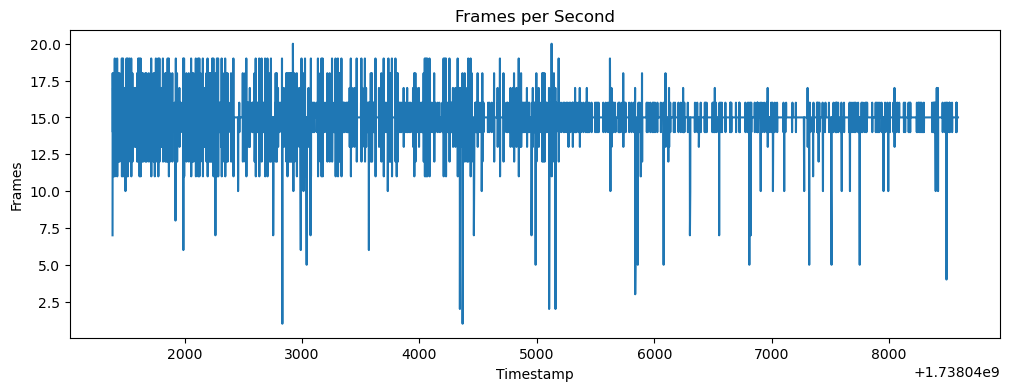

In [218]:
plt.figure(figsize=(12,4))
plt.plot(fps_df['timestamp'], fps_df['frames'])
plt.xlabel("Timestamp")
plt.ylabel("Frames")
plt.title("Frames per Second")
plt.show()

**On average we have almost 15 frames per one second**

In [219]:
display(fps_df['frames'].mean())

14.932978126752664

**We have 2 hours of data in total**

In [220]:
# data aggregated per second
per_sec = df.groupby("timestamp")["car_count"].mean()
per_sec = per_sec.to_frame().reset_index()

display(len(per_sec) / 60)

118.86666666666666

In [221]:
display(per_sec.head(10))

,timestamp,car_count
0,1738041386,11.285714
1,1738041387,11.666667
2,1738041388,13.400000
3,1738041389,12.928571
4,1738041390,12.352941
5,1738041391,12.800000
6,1738041392,11.266667
7,1738041393,11.733333
8,1738041394,11.533333
9,1738041395,8.722222


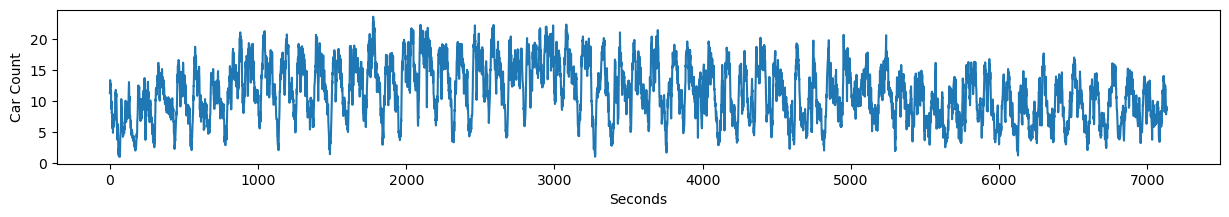

In [222]:
plt.figure(figsize=(15, 2))
plt.plot(per_sec["car_count"])
plt.xlabel("Seconds")
plt.ylabel("Car Count")
plt.show()

<hr>

## Features Engineering for GBM

**We will add lags, and rolling features. Commonly used practice for GBM forecasting.**

In [223]:
per_sec["dt"] = pd.to_datetime(per_sec["timestamp"], unit="s") 

In [224]:
horizon = 60

# 1, 1.5, 2, 5, 10 minutes ago
lag_list = [60, 90, 120, 300, 600]
for lag in lag_list:
    per_sec[f"car_count_lag_{lag}"] = per_sec["car_count"].shift(lag)

In [225]:
# rollings shifted by 60 seconds    
window_list = [30, 60, 120, 300]
for window in window_list:
    past = per_sec["car_count"].shift(horizon)
    per_sec[f"rllg_mean_{window}"] = past.rolling(window).mean()
    per_sec[f"rllg_std_{window}"]  = past.rolling(window).std()

In [226]:
# trend features, traffice rising or declining?
per_sec["trend_60_120"] = per_sec["car_count_lag_60"] - per_sec["car_count_lag_120"]
per_sec["trend_mean_60_300"] = per_sec["rllg_mean_60"] - per_sec["rllg_mean_300"]

In [227]:
per_sec = per_sec.drop(['timestamp'], axis=1)

In [228]:
per_sec.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7132 entries, 0 to 7131
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   car_count          7132 non-null   float64       
 1   dt                 7132 non-null   datetime64[ns]
 2   car_count_lag_60   7072 non-null   float64       
 3   car_count_lag_90   7042 non-null   float64       
 4   car_count_lag_120  7012 non-null   float64       
 5   car_count_lag_300  6832 non-null   float64       
 6   car_count_lag_600  6532 non-null   float64       
 7   rllg_mean_30       7043 non-null   float64       
 8   rllg_std_30        7043 non-null   float64       
 9   rllg_mean_60       7013 non-null   float64       
 10  rllg_std_60        7013 non-null   float64       
 11  rllg_mean_120      6953 non-null   float64       
 12  rllg_std_120       6953 non-null   float64       
 13  rllg_mean_300      6773 non-null   float64       
 14  rllg_std

<hr>

**WAPE score** <br>
Weighted Absolute Percentage Error: total absolute error divided by total actual values. <br>
* **MAPE** breaks when `y_true = 0`, **WAPE** doesn't
* **MAPE** gives equal weight to all observations, so small-value rows can dominate, **WAPE** is more stable

**`WAPE = 20%`** means total predicted volume is off by 20% relative to total actual volume.

In [229]:
def wape_nonzero(y_true, y_pred, eps=1e-9):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    m = (y_true != 0)
    if m.sum() == 0:
        return 0.0
    return np.sum(np.abs(y_true[m] - y_pred[m])) / (np.sum(np.abs(y_true[m])) + eps)

wape_nonzero_scorer = make_scorer(wape_nonzero, greater_is_better=False)

<hr>

## Train-Test Sets

**We will use 60 last seconds as a test set, because using actual frames will bring us to much noise for the models.**

In [230]:
# cut off date
cutoff_date = pd.Timestamp('2025-01-28 07:15:26')

# train-test split
train_df = per_sec[per_sec["dt"] <= cutoff_date].copy()
test_df  = per_sec[per_sec["dt"] > cutoff_date].copy()

**Train** set date period 

In [231]:
display(train_df["dt"].min())
display(train_df["dt"].max())

Timestamp('2025-01-28 05:16:26')

Timestamp('2025-01-28 07:15:26')

**Test** set date period 

In [232]:
display(test_df["dt"].min())
display(test_df["dt"].max())

Timestamp('2025-01-28 07:15:27')

Timestamp('2025-01-28 07:16:26')

In [233]:
# train features & target
X_train = train_df.drop(columns=['car_count'])
y_train = train_df['car_count']

# test features & target
X_test = test_df.drop(columns=['car_count'])
y_test = test_df['car_count']

<hr>

## Models Forecasting

### ARIMA Baseline

Using ARIMA model for a baseline as a **stat-only method**

In [234]:
# model loading
horizon = len(y_test)

arima = ARIMA(train_df['car_count'].values.astype(np.float32), order=(5, 1, 0)).fit()

In [235]:
# forecasting
y_pred = arima.forecast(steps=horizon)

In [236]:
# saving predictions
y_pred = y_pred.astype(np.float32)
test_df['pred_arima'] = y_pred

In [237]:
# metrics
eps = 1e-9
mask = np.abs(y_test) > eps

mae_arima = np.mean(np.abs(y_test - y_pred))
mape_arima = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_arima = wape_nonzero(y_test, y_pred) * 100

<hr>

### GBM

In [238]:
# time-series cross validation, used because regular CV is invalid
tscv = TimeSeriesSplit(n_splits=2)

# CatBoost model with GPU training type
catboost = CatBoostRegressor(task_type="GPU")

# parameter variation for GridSearch
param_grid = {
    "depth": [-1, 6, 10],
    "learning_rate": [0.01, 0.1, 0.5],
    "l2_leaf_reg": [30, 100],
    "iterations": [6000],
    "min_data_in_leaf": [50, 200, 800],
    "random_strength": [0.5, 2.0],
}

In [239]:
grid = GridSearchCV(
    estimator=catboost,
    param_grid=param_grid,
    cv=tscv,
    scoring={"wape": wape_nonzero_scorer, "mae": "neg_mean_absolute_error"},
    refit="wape",
    verbose=2,
    n_jobs=1
)

```
%%time

# model training
grid.fit(X_train, y_train, early_stopping_rounds=300, verbose=6000)
```

``` 
CPU times: total: 5h 11min 12s
Wall time: 4h 33min 24s
```

```
# trained model parameters
best_model = grid.best_estimator_

# saving model
best_model.save_model("gbm.cbm")
```

**4.5 hours for training GBM** 

<hr>

In [240]:
# model loading
catboost = CatBoostRegressor()
catboost.load_model("gbm.cbm")

In [241]:
# model parameters
catboost.get_params()

{'random_strength': 0.5,
 'od_wait': 300,
 'od_type': 'Iter',
 'verbose': 6000,
 'iterations': 6000,
 'loss_function': 'RMSE',
 'l2_leaf_reg': 100,
 'task_type': 'GPU',
 'depth': 10,
 'min_data_in_leaf': 50,
 'learning_rate': 0.01}

In [242]:
# prediction on test set
y_pred = catboost.predict(X_test)
test_df['pred_gbm'] = y_pred

<hr>

In [243]:
# MAE
mae_gbm = np.mean(np.abs(y_test - y_pred))

# MAPE
mape_gbm = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100

# WAPE
wape_gbm = wape_nonzero(y_test, y_pred) * 100

**naive baseline:** predict `car_count` using the value from 60s ago <br>
reuse the same `car_count_lag_60` column already built on the full series

In [244]:
# naive baseline
naive_pred = test_df["car_count_lag_60"].values.astype(np.float32)

mask_naive = ~np.isnan(naive_pred) & (np.abs(y_test) > eps)

mae_naive  = np.mean(np.abs(y_test[mask_naive] - naive_pred[mask_naive]))
mape_naive = np.mean(np.abs((y_test[mask_naive] - naive_pred[mask_naive]) / y_test[mask_naive])) * 100
wape_naive = wape_nonzero(y_test[mask_naive], naive_pred[mask_naive]) * 100

In [245]:
metrics = pd.DataFrame([[round(mae_naive, 2), round(mape_naive, 2), round(wape_naive, 2)], 
                        [round(mae_arima, 2), round(mape_arima, 2), round(wape_arima, 2)], 
                        [round(mae_gbm, 2), round(mape_gbm, 2), round(wape_gbm, 2)], 
                        [0, 0, 0],
                        [0, 0, 0]], 
                       index=["Naive Baseline", "ARIMA Baseline", "GBM (Catboost)", "TimesFM", "Chronos"], 
                       columns=["MAE", "MAPE %", "WAPE %"])

In [246]:
display(metrics)

,MAE,MAPE %,WAPE %
Naive Baseline,3.21,42.70,36.90
ARIMA Baseline,2.55,39.95,29.33
GBM (Catboost),2.11,29.04,24.28
TimesFM,0.00,0.00,0.00
Chronos,0.00,0.00,0.00


<hr>

In [247]:
# list of additional GBM features
features_list = list(train_df.columns)

for i in ['car_count', 'dt']:
    features_list.remove(i)

display(features_list)

['car_count_lag_60',
 'car_count_lag_90',
 'car_count_lag_120',
 'car_count_lag_300',
 'car_count_lag_600',
 'rllg_mean_30',
 'rllg_std_30',
 'rllg_mean_60',
 'rllg_std_60',
 'rllg_mean_120',
 'rllg_std_120',
 'rllg_mean_300',
 'rllg_std_300',
 'trend_60_120',
 'trend_mean_60_300']

In [248]:
# removing GBM features from the data
train_df = train_df.drop(columns=features_list)
test_df = test_df.drop(columns=features_list)

<hr>

## Foundation Models: Three Architectural Families


### TimesFM (Google): Patch-based
* Patch = a small chunk of consecutive time points grouped together (e.g. 32 points).
* Series is sliced into patches, each patch is treated as one "token", similar to how Vision Transformers split an image into patches.
* **Raw numeric values** are kept inside each patch, they **are not converted into words or symbols.**
* Decoder-only transformer that predicts the next patch.

### Chronos (Amazon): Tokenization/Quantization
* **Turn continuous numbers into discrete tokens**, then treat forecasting as a language-modeling problem.
* Scale the series -> quantize it -> bin real values into a fixed vocabulary (e.g. value 3.7 → token #142).
* Once every number is a token, standard language model (Chronos uses a T5 architecture) is trained with cross-entropy loss, **exactly like next-word prediction**.
* Quantization = continuous values -> discrete symbols.

### TiRex (NXAI): xLSTM-based

* Not transformer, **built on xLSTM** (an enhanced LSTM) instead.
* Transformers dominate zero-shot forecasting but often underperform recurrent models (LSTMs) on time series, while classic LSTMs **lack strong in-context learning**. xLSTM aims to combine both strengths.
* State-tracking: the model **continuously updates a hidden state** over time, which helps on long forecast horizons (transformers lack this).
* Still uses patching, but runs it through a recurrent backbone instead of attention.
* Only **35M parameters** (much smaller than TimesFM2.0 at 500M or Chronos at 200M), yet should achieve state-of-the-art zero-shot results.

<hr>

### TimesFM

In [249]:
# model loading
timesfm_model = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")

In [250]:
# predict horizon & max_context length
horizon = len(y_test)
max_context = len(y_train)

In [251]:
# model configure
timesfm_model.compile(
    timesfm.ForecastConfig(
        max_context=max_context, # historical context, train_df lenght
        max_horizon=256, # ceiling of forecasting horizon
        normalize_inputs=True,
        use_continuous_quantile_head=True, # 
        force_flip_invariance=True,
        infer_is_positive=False, # temperature can go negative
        fix_quantile_crossing=True,
    )
)

In [252]:
# context (train set) for model to look on
context = train_df['car_count'].values.astype(np.float32)

# forecasting
point_forecast, quantile_forecast = timesfm_model.forecast(
    horizon=horizon,
    inputs=[context], # single series -> list with one array
)

In [253]:
# predicted values
y_pred = point_forecast[0]
test_df['pred_timesfm'] = y_pred

In [254]:
# metrics
mae_timesfm = np.mean(np.abs(y_test - y_pred))
mape_timesfm = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_timesfm = wape_nonzero(y_test, y_pred) * 100

metrics.loc["TimesFM"] = [round(mae_timesfm, 2), round(mape_timesfm, 2), round(wape_timesfm, 2)]

In [255]:
display(metrics)

,MAE,MAPE %,WAPE %
Naive Baseline,3.21,42.70,36.90
ARIMA Baseline,2.55,39.95,29.33
GBM (Catboost),2.11,29.04,24.28
TimesFM,2.26,31.81,25.98
Chronos,0.00,0.00,0.00


<hr>

### Chronos

Pandas DFs to AutoGluon TimeSeriesDF 

In [256]:
train_df = train_df.copy()
train_df["item_id"] = "car_count"

train_data = TimeSeriesDataFrame.from_data_frame(
    train_df,
    id_column="item_id",
    timestamp_column="dt"
)

test_df = test_df.copy()
test_df["item_id"] = "car_count"

test_data = TimeSeriesDataFrame.from_data_frame(
    test_df,
    id_column="item_id",
    timestamp_column="dt"
)

<hr>

In [257]:
# model loading
model = TimeSeriesPredictor(
    prediction_length=horizon,
    target="car_count",
    freq="S",
).fit(
    train_data,
    hyperparameters={
        "Chronos2": {"context_length": None},},
    presets="chronos2",
)

Beginning AutoGluon training...
AutoGluon will save models to 'C:\Users\whois\Desktop\New folder\unic\COMP494 Final Project (Thesis)\AutogluonModels\ag-20261025_134600'
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.11.7
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          16
Pytorch Version:    2.5.1+cu121
CUDA Version:       12.1
GPU Memory:         GPU 0: 5.27/8.00 GB
Total GPU Memory:   Free: 5.27 GB, Allocated: 2.73 GB, Total: 8.00 GB
GPU Count:          1
Memory Avail:       9.51 GB / 31.19 GB (30.5%)
Disk Space Avail:   11.78 GB / 464.77 GB (2.5%)
Setting presets to: chronos2

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': WQL,
 'freq': 'S',
 'hyperparameters': {'Chronos2': {'context_length': None}},
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 60,
 'quantile_levels': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
 'random_see

In [258]:
pred = model.predict(train_data, 
                     model='Chronos2',)

data with frequency 'IRREG' has been resampled to frequency 'S'.


In [259]:
# saving predictions
y_pred = pred['mean'].values.astype(np.float32)
test_df['pred_chronos'] = y_pred

In [260]:
# metrics
mae_chronos = np.mean(np.abs(y_test - y_pred))
mape_chronos = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_chronos = wape_nonzero(y_test, y_pred) * 100

metrics.loc["Chronos"] = [round(mae_chronos, 2), round(mape_chronos, 2), round(wape_chronos, 2)]

In [261]:
display(metrics)

,MAE,MAPE %,WAPE %
Naive Baseline,3.21,42.70,36.90
ARIMA Baseline,2.55,39.95,29.33
GBM (Catboost),2.11,29.04,24.28
TimesFM,2.26,31.81,25.98
Chronos,1.73,24.82,19.87


<hr>

### Chronos Fine-Tuned

In [262]:
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.5.1+cu121
True
NVIDIA GeForce RTX 4060


<hr>

```
# model loading
model = TimeSeriesPredictor(
    prediction_length=horizon,
    target="car_count",
    freq="S",
    path="saved_models/chronos2_lora",
).fit(
    train_data,
    hyperparameters={
        "Chronos2": {"fine_tune":True, 'fine_tune_mode':'lora', "ag_args":{"name_suffix": "FineTuned"}}},
    presets="chronos2",
)
```

**280 seconds for fine-tuning Chronos** 

In [263]:
# loading tuned Chronos model
model = TimeSeriesPredictor.load("saved_models/chronos2_lora")

Loading predictor from path C:\Users\whois\Desktop\New folder\unic\COMP494 Final Project (Thesis)\saved_models\chronos2_lora


In [264]:
pred = model.predict(train_data, 
                     model='Chronos2FineTuned',)

data with frequency 'IRREG' has been resampled to frequency 'S'.


In [265]:
# saving predictions
y_pred = pred['mean'].values.astype(np.float32)
test_df['pred_chronos_ft'] = y_pred

In [266]:
# metrics
mae_chronos_ft = np.mean(np.abs(y_test - y_pred))
mape_chronos_ft = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_chronos_ft = wape_nonzero(y_test, y_pred) * 100

metrics.loc["Chronos Fine-Tuned"] = [round(mae_chronos_ft, 2), round(mape_chronos_ft, 2), round(wape_chronos_ft, 2)]

In [267]:
# final metrics dataset
display(metrics)

,MAE,MAPE %,WAPE %
Naive Baseline,3.21,42.70,36.90
ARIMA Baseline,2.55,39.95,29.33
GBM (Catboost),2.11,29.04,24.28
TimesFM,2.26,31.81,25.98
Chronos,1.73,24.82,19.87
Chronos Fine-Tuned,1.70,23.33,19.57


<hr>

### TiRex

In [268]:
model = load_model("NX-AI/TiRex", device="cuda")

In [269]:
# single series shape
context = torch.tensor(context).unsqueeze(0)

# TiRex returns quantiles & mean
quantiles, mean = model.forecast(context=context, prediction_length=horizon)

# make sure its plain numpy array
if torch.is_tensor(mean):
    mean = mean.cpu().numpy()
else: np.asarray(mean)

In [270]:
# predictions
y_pred = mean[0]
test_df['pred_tirex'] = y_pred

In [271]:
# metrics
mae_tirex  = np.mean(np.abs(y_test - y_pred))
mape_tirex = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
wape_tirex = wape_nonzero(y_test, y_pred) * 100

metrics.loc["TiRex"] = [round(mae_tirex, 2), round(mape_tirex, 2), round(wape_tirex, 2)]

In [272]:
# final metrics dataset
display(metrics)

,MAE,MAPE %,WAPE %
Naive Baseline,3.21,42.70,36.90
ARIMA Baseline,2.55,39.95,29.33
GBM (Catboost),2.11,29.04,24.28
TimesFM,2.26,31.81,25.98
Chronos,1.73,24.82,19.87
Chronos Fine-Tuned,1.70,23.33,19.57
TiRex,2.21,31.54,25.39


<hr>

## Forecasting Analysis

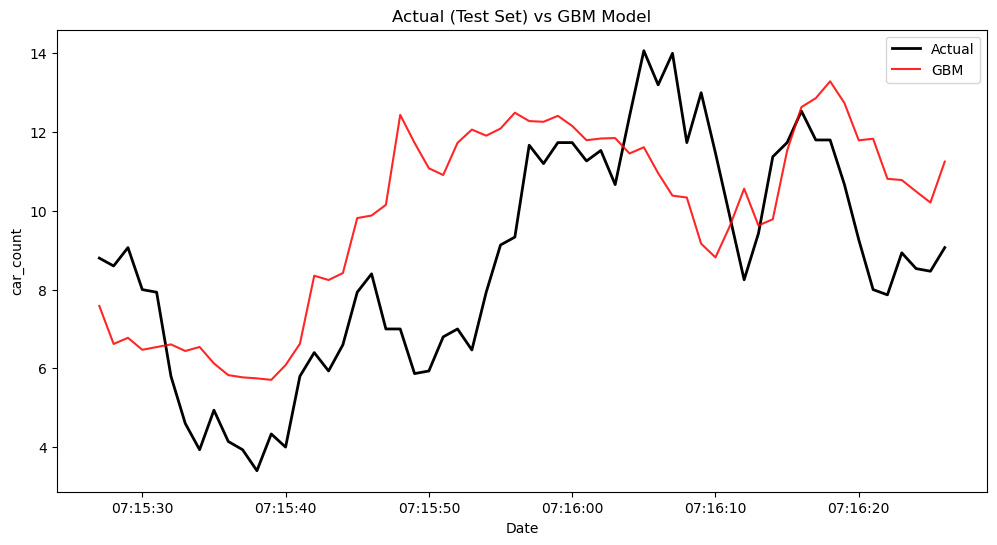

In [273]:
plt.figure(figsize=(12, 6))
plt.plot(test_df['dt'], y_test, label='Actual', c='0', linewidth=2)
plt.plot(test_df['dt'], test_df['pred_gbm'], label='GBM', c='red', alpha=0.85)
plt.title('Actual (Test Set) vs GBM Model')
plt.xlabel('Date')
plt.ylabel('car_count')
plt.legend()
plt.show()

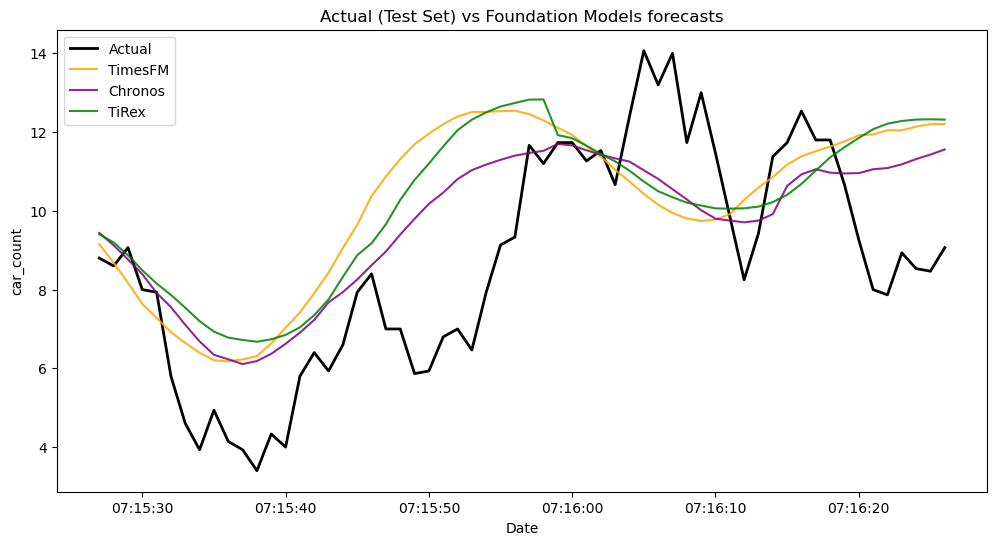

In [274]:
plt.figure(figsize=(12, 6))
plt.plot(test_df['dt'], y_test, label='Actual', c='0', linewidth=2)
plt.plot(test_df['dt'], test_df['pred_timesfm'], label='TimesFM', c='orange', alpha=0.85)
plt.plot(test_df['dt'], test_df['pred_chronos'], label='Chronos', c='purple', alpha=0.85)
plt.plot(test_df['dt'], test_df['pred_tirex'], label='TiRex', c='green', alpha=0.85)
plt.title('Actual (Test Set) vs Foundation Models forecasts')
plt.xlabel('Date')
plt.ylabel('car_count')
plt.legend()
plt.show()

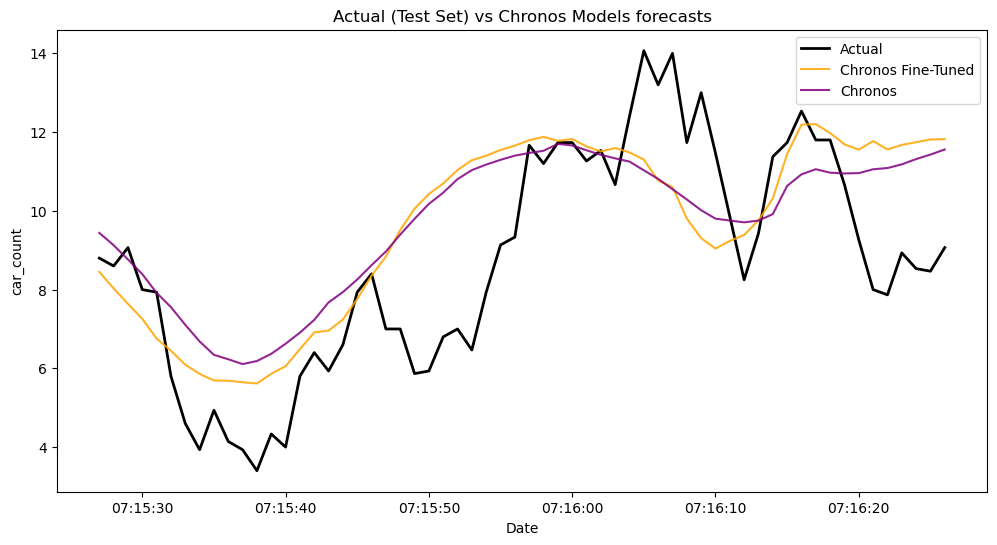

In [275]:
plt.figure(figsize=(12, 6))
plt.plot(test_df['dt'], y_test, label='Actual', c='0', linewidth=2)
plt.plot(test_df['dt'], test_df['pred_chronos_ft'], label='Chronos Fine-Tuned', c='orange', alpha=0.85)
plt.plot(test_df['dt'], test_df['pred_chronos'], label='Chronos', c='purple', alpha=0.85)
plt.title('Actual (Test Set) vs Chronos Models forecasts')
plt.xlabel('Date')
plt.ylabel('car_count')
plt.legend()
plt.show()

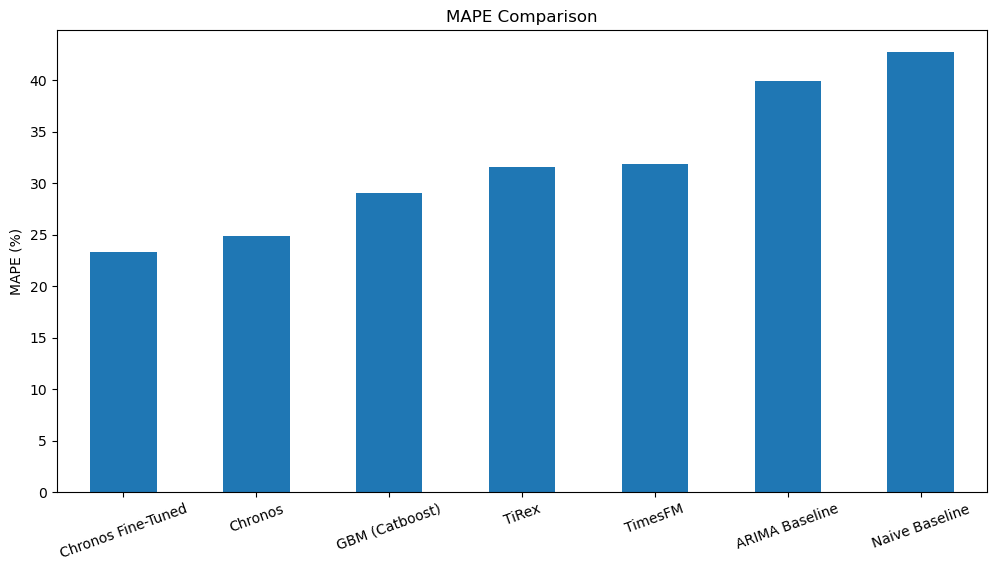

In [276]:
plt.figure(figsize=(12,6))
metrics['MAPE %'].sort_values(ascending=True).plot(kind='bar')
plt.ylabel('MAPE (%)')
plt.title('MAPE Comparison')
plt.xticks(rotation=20)
plt.show()

<hr>

# Results

* All the models are doing better than chosen Naive baseline (predict same as 60 seconds before)
* Foundation models `TimesFM` & `Chronos` are producing visibly **smooth forecasts** that track the trend of series, but they are **failing to reproduce short term volatility** (spikes on the chart)
* `Chronos Fine-Tuned` is **the best model overall** (MAE 1.70, MAPE 23.33%, WAPE 19.57%), followed closely by zero-shot `Chronos` (MAE 1.73, MAPE 24.82%, WAPE 19.87%)
* `GBM` model comes **third** (MAE 2.11, MAPE 29.04%, WAPE 24.28%), behind both `Chronos` variants, even though it requires feature engineering `lags` & `rollings` and **time-consuming** training/hyperparameter search (4.5 hours total). On the chart its forecast is less smooth and reacts to short fluctuations, but it **systematically overestimates** the series (between 07:15:40 and 07:15:55 it predicts 8–12 while actual values are 4–10), and it misses the main peak around 07:16:05. So reacting to volatility alone does not translate into lower error if the level of the forecast is off
* `Chronos Fine-Tuned` on LoRA (Low-Rank Adaptation) adapters is showing **slightly better performance** than zero-shot `Chronos`, we can also see this on the chart: prediction is trying to capture short fluctuations and becomes a little bit less smooth. We assume this could be even better if we had `>100 time series` as AutoGluon suggesting:
  * *We recommend fine-tuning only when you have a reasonable number of time series and sufficient historical data (e.g., >100 time series with a median history length larger than 3 * prediction_length), as limited data can lead to overfitting or degraded performance. If you observe degraded accuracy, we recommend increasing the size of the training data and experimenting with different fine-tuning hyperparameters.*
* `TiRex` performs **almost identically** to `TimesFM` (MAE 2.21 vs 2.26, WAPE 25.39 vs 25.98), staying clearly behind both `Chronos` variants and slightly behind `GBM` (MAE 2.21 vs 2.11). Like the other foundation models, it produces a smooth trend-following curve that misses the short-term spikes, **same volatility limitation**.
* Noticeably, `TiRex` reaches this accuracy **with only 35M parameters** vs `TimesFM` 200M, with recurrent xLSTM backbone vs Transformer, so we can say that there is an **advancement** in terms of power and **resources for computation**.

Foundation models demonstrated strong forecasting performance with considerably less manual feature engineering compared to traditional methods such as GBM. In this experiment both `Chronos` variants outperformed the tuned `GBM` on all metrics, so for this data the trade-off between implementation effort and forecasting accuracy favours foundation models: better accuracy with no feature engineering and no lengthy hyperparameter search.

Additionally, there are performance improvements from TimesFM to Chronos and from zero-shot to fine-tuned Chronos indicating the advancement of foundation models, we can suggest that they will play an increasingly important role in time-series forecasting as the technology continues to mature.

* `Chronos` (Chronos 2) outperforms `TimesFM` (TimesFM 2.5) on this dataset (MAE 1.73 vs 2.26, WAPE 19.87 vs 25.98). Unlike the original `Chronos`, which tokenized values into discrete bins, both `Chronos 2` and `TimesFM 2.5` use **patching** and both output a **median point forecast**, so the difference is not caused by tokenization or by the forecasting objective. We attribute it mainly to **pretraining data and normalization**: `TimesFM` is pretrained largely on **strongly seasonal** web data (Google Trends, Wikipedia pageviews) and is strongest at capturing repeating periodic patterns, while `Chronos 2` corpus includes large amounts of synthetic **irregular and autoregressive** series and uses asinh-based normalization that is robust to spikes. Experiment 1 contains **no seasonality**, so `TimesFM` advantage is unused: on the chart it reacts to the upward trend earliest and overshoots the most (12.5 around 07:15:50 while actual values are 6–7), while `Chronos` follows the same trend in a more damped way. Part of the gap may also reflect overall model strength, as `Chronos 2` outperforms `TimesFM 2.5` on the GIFT-Eval benchmark as well. We expect the gap could shrink on data with clear seasonal patterns.

In [277]:
display(metrics.sort_values('MAE', ascending=False))

,MAE,MAPE %,WAPE %
Naive Baseline,3.21,42.70,36.90
ARIMA Baseline,2.55,39.95,29.33
TimesFM,2.26,31.81,25.98
TiRex,2.21,31.54,25.39
GBM (Catboost),2.11,29.04,24.28
Chronos,1.73,24.82,19.87
Chronos Fine-Tuned,1.70,23.33,19.57


## Note

* This investigation could be extended by comparing the models on their predicted quantiles, which some models produce by default. For simplicity, however, we use only the point forecast `mean`.  